In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pickle
import json
import os
import pandas as pd
from IPython.display import display
from torch.utils.data import DataLoader

from src.trainer_dann import TrainerLSTM, TrainerDANN
from src.utils import evaluation
from src.config import NATIVE_MODEL_BY_DOMAIN, DEVICE

c:\Users\alice\master_thesis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def display_classification_reports(reports):
    for split_name, split_data in reports.items():
        print(f"\n {split_name} - overall")
        overall_df = pd.DataFrame(split_data["overall"]).transpose()
        display(overall_df)

        for domain, domain_report in split_data["domains"].items():
            print(f"\n {split_name} - {domain}")
            domain_df = pd.DataFrame(domain_report).transpose()
            display(domain_df)

In [3]:
results_dict = {"frame_sampler": "outputs/results/frame_sampler", "frame_dann_sampler": "outputs/results/frame_dann_sampler"}
all_reports = {}

Confusion Matrices for frame_sampler experiment


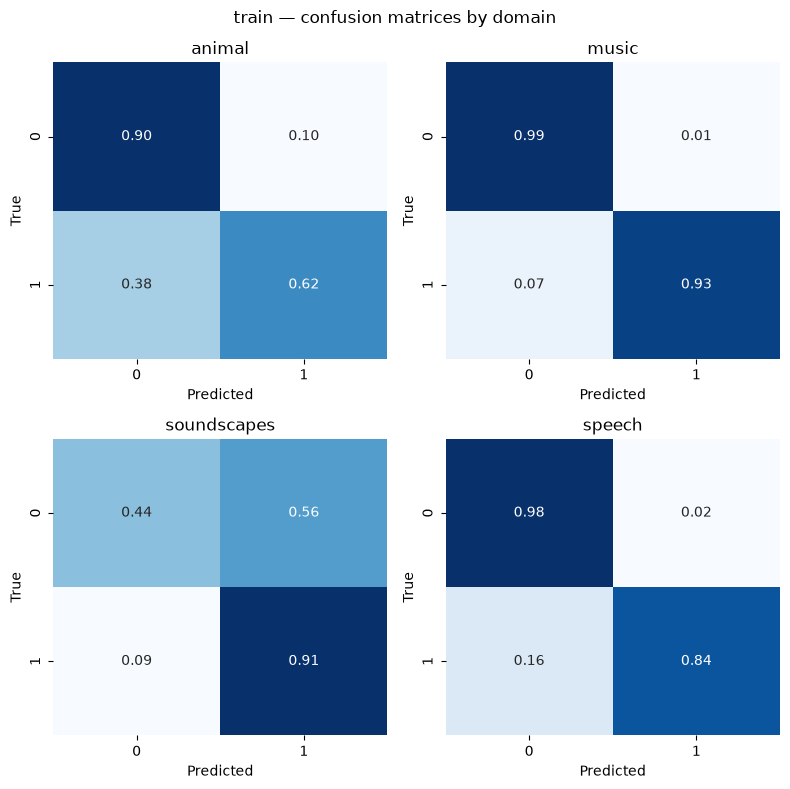

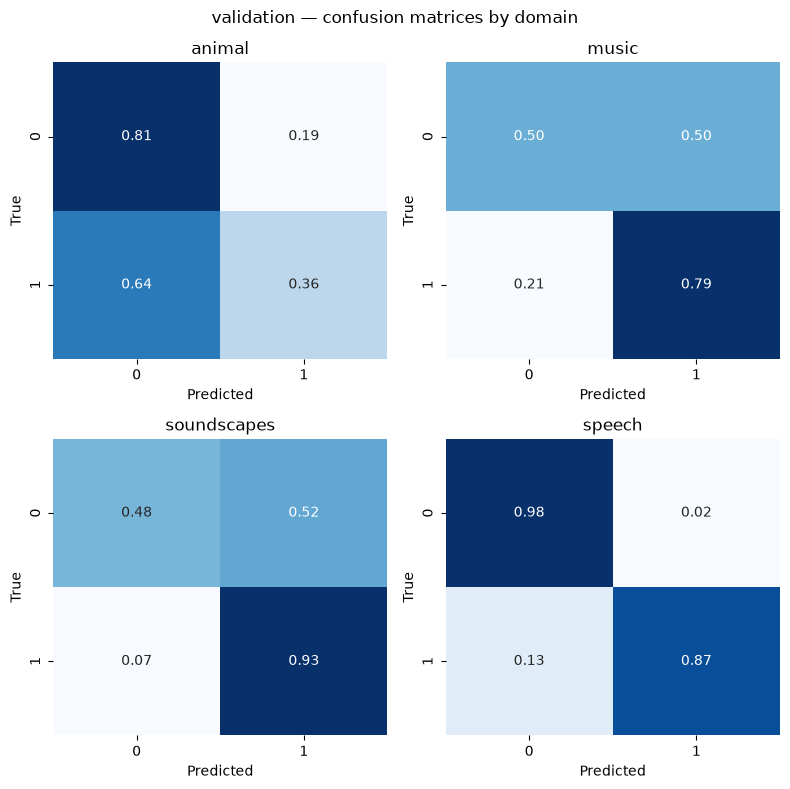

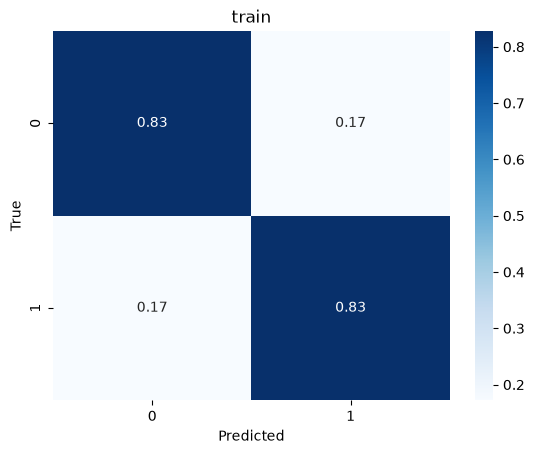

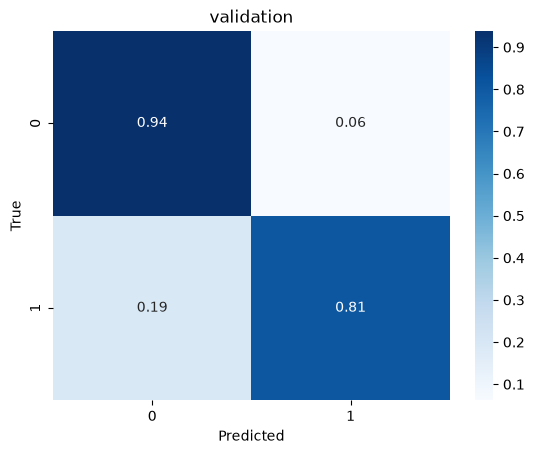

Confusion Matrices for frame_dann_sampler experiment


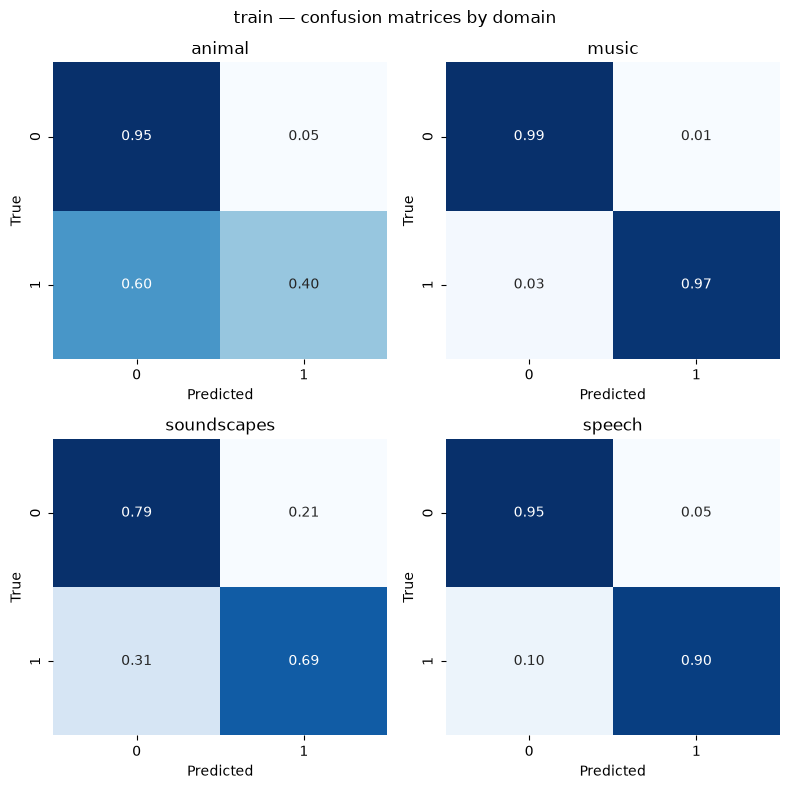

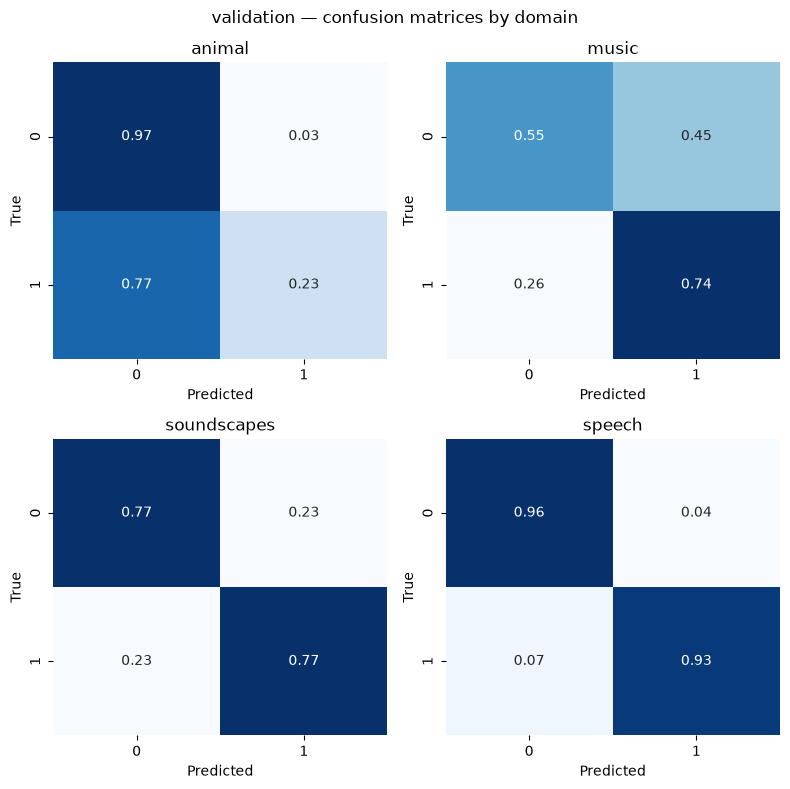

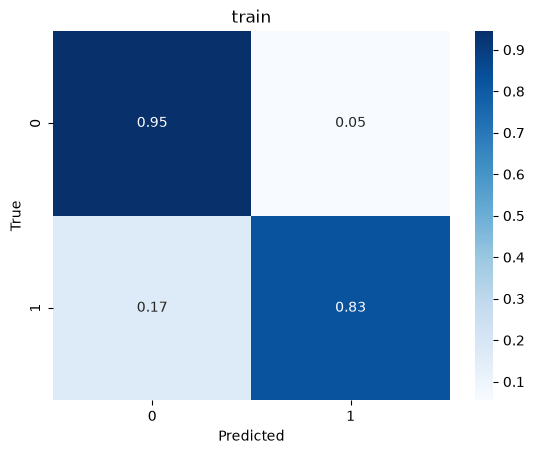

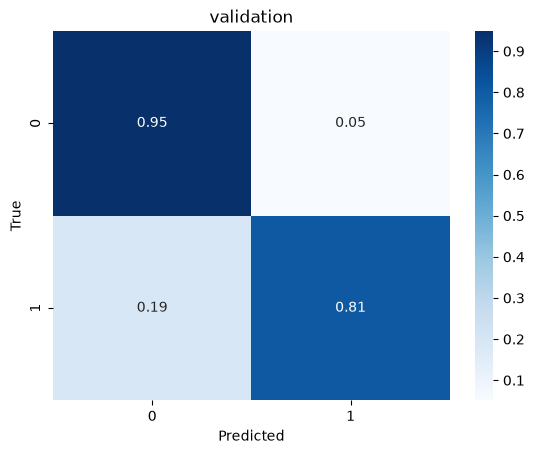

In [4]:
for run in ("frame_sampler", "frame_dann_sampler"):
    splits = [("train", f"{results_dict[run]}/train_results.pt"), ("validation", f"{results_dict[run]}/validation_results.pt")]

    conf_mat_outdir = os.path.join("outputs/plots/confusion_matrices", run)
    tables_outdir = os.path.join("outputs/tables", run)

    for d in (conf_mat_outdir, tables_outdir):
        os.makedirs(d, exist_ok=True)


    reports = evaluation.compute_classification_reports(None, splits)
    all_reports[run] = reports
    #display_classification_reports(reports)

    with open(f"outputs/tables/{run}/classification_reports.json", "w") as f:
        json.dump(reports, f, indent=2)

    print(f"Confusion Matrices for {run} experiment")
    for split_name, pt_path in splits:
        evaluation.save_combined_confusion_matrix(None, pt_path, split_name, output_dir=f"plots/confusion_matrices/{run}")

    evaluation.save_confusion_matrices(None, splits)


In [6]:
for split_name in ("train", "validation"):
    tables = {}
    for run in ("frame_sampler", "frame_dann_sampler"):
        tables[run] = evaluation.build_summary_table(all_reports[run], split_name=split_name)

    comparison = pd.concat(tables, axis=1)
    print(split_name)
    display(comparison)
    

train


frame_sampler                                                 \
                 accuracy balanced_accuracy precision_macro recall_macro   
domain                                                                     
animal           0.761621          0.762255        0.784228     0.762255   
music            0.963537          0.963257        0.965605     0.963257   
soundscapes      0.671515          0.675192        0.725778     0.675192   
speech           0.910059          0.909876        0.918059     0.909876   

                      frame_dann_sampler                                    \
             f1_macro           accuracy balanced_accuracy precision_macro   
domain                                                                       
animal       0.757076           0.834504          0.675969        0.765275   
music        0.963478           0.977162          0.982475        0.961924   
soundscapes  0.653320           0.739938          0.739989        0.742318   
speech       0.909600           0.940192          0.925717        0.900052   

                                    
            recall_macro  f1_macro  
domain                              
animal          0.675969  0.702664  
music           0.982475  0.971511  
soundscapes     0.739989  0.739325  
speech          0.925717  0.912018

validation


frame_sampler                                                 \
                 accuracy balanced_accuracy precision_macro recall_macro   
domain                                                                     
animal           0.707937          0.589071        0.590792     0.589071   
music            0.714286          0.644737        0.636364     0.644737   
soundscapes      0.704918          0.704918        0.759619     0.704918   
speech           0.958610          0.925703        0.946440     0.925703   

                      frame_dann_sampler                                    \
             f1_macro           accuracy balanced_accuracy precision_macro   
domain                                                                       
animal       0.589890           0.793651          0.598267        0.741724   
music        0.639881           0.688312          0.643421        0.623303   
soundscapes  0.688511           0.770492          0.770492        0.770492   
speech       0.935587           0.951967          0.942422        0.917385   

                                    
            recall_macro  f1_macro  
domain                              
animal          0.598267  0.610512  
music           0.643421  0.628019  
soundscapes     0.770492  0.770492  
speech          0.942422  0.929125

FRAME_SAMPLER


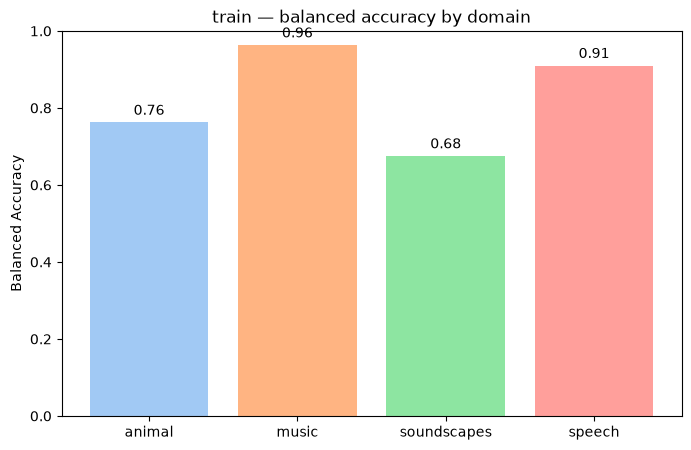

FRAME_SAMPLER


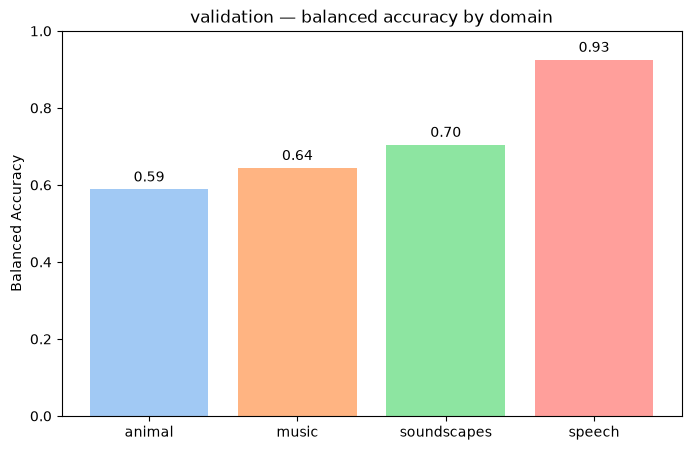

FRAME_DANN_SAMPLER


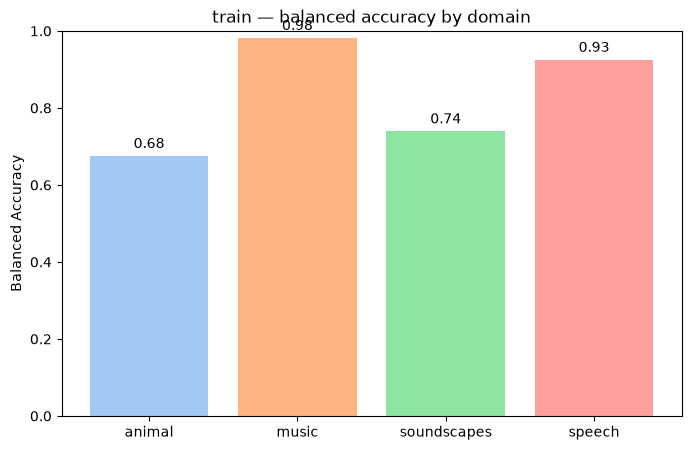

FRAME_DANN_SAMPLER


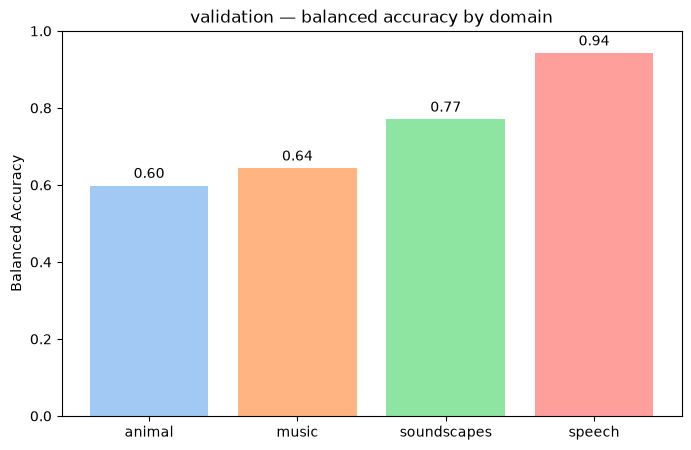

In [7]:
for run in ("frame_sampler", "frame_dann_sampler"):
    for split_name in ("train", "validation"):
        print(f"{run.upper()}")
        evaluation.plot_domain_metric_bar(all_reports[run], split_name=split_name, metric="balanced_accuracy", filename=f"plots/{run}/{split_name}_domain_summary.png")

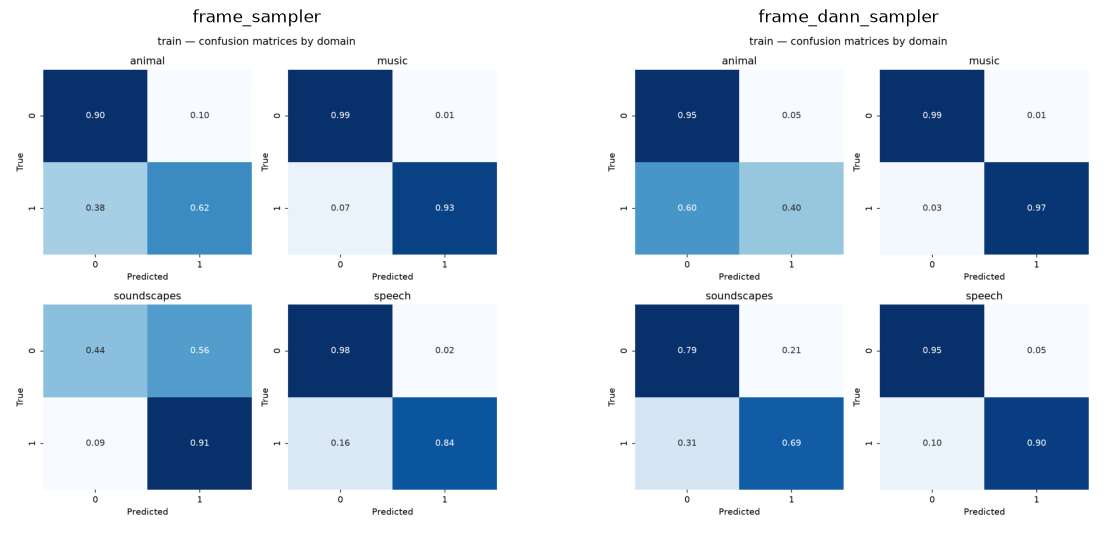

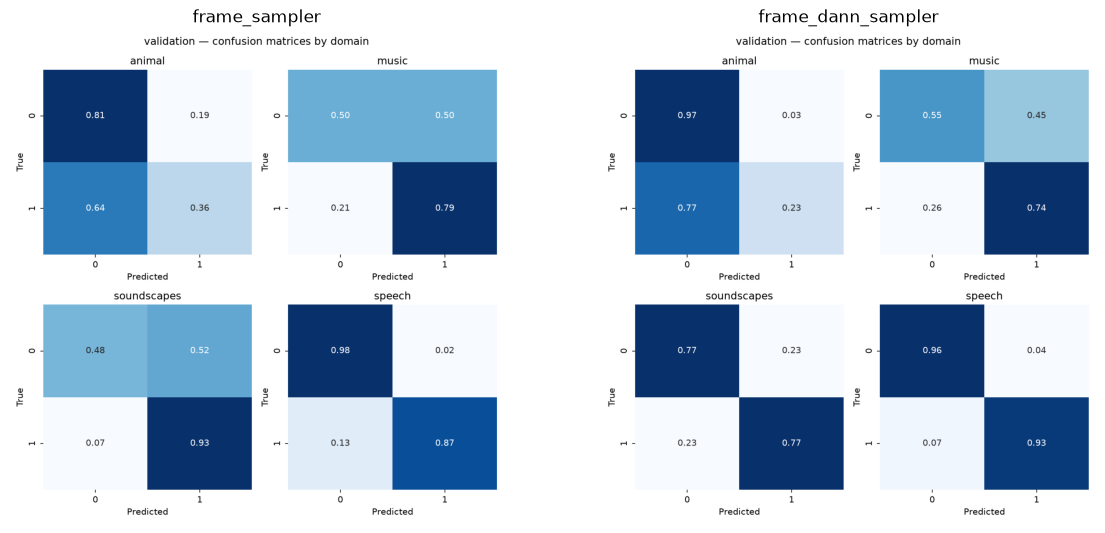

In [8]:
for split_name in ("train", "validation"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, run in zip(axes, ("frame_sampler", "frame_dann_sampler")):
        img = mpimg.imread(f"outputs/plots/confusion_matrices/{run}/{split_name}_combined_cf_matrix.png")
        ax.imshow(img)
        ax.set_title(run)
        ax.axis("off")
    plt.show()